# Disconnected Gaussian tails — S2 prototype

Estimate P(|X|>a), X~N(0,1). Compare direct MC, N(a,1), a balanced two-tail mixture, and a 10% defensive mixture. Ordinary IS uses the full mixture density; it is not self-normalized. See informe.md for prior art and assumptions.

In [1]:
import json, csv
from pathlib import Path
from src.estimators import truth, population_variance
r = json.loads(Path('benchmarks/results.json').read_text())
print('Success gate:', r['success'])
print('RMSE ratio:', r['rmse_ratio'])
for name, row in r['selected'].items():
    print(name, 'mean=', row['mean'], 'relative RMSE=', row['relative_rmse'], 'coverage=', row['coverage_95'])

Success gate: True
RMSE ratio: 0.025446408975887225
direct mean= 5.250000000000001e-05 relative RMSE= 0.6337155869865688 coverage= 0.775
single_tilt mean= 3.15606786497916e-05 relative RMSE= 0.5018070885725991 coverage= 0.0
balanced mean= 6.336006289150364e-05 relative RMSE= 0.016125786000854667 coverage= 0.925
defensive mean= 6.363787412819698e-05 relative RMSE= 0.017356200008867916 coverage= 0.95


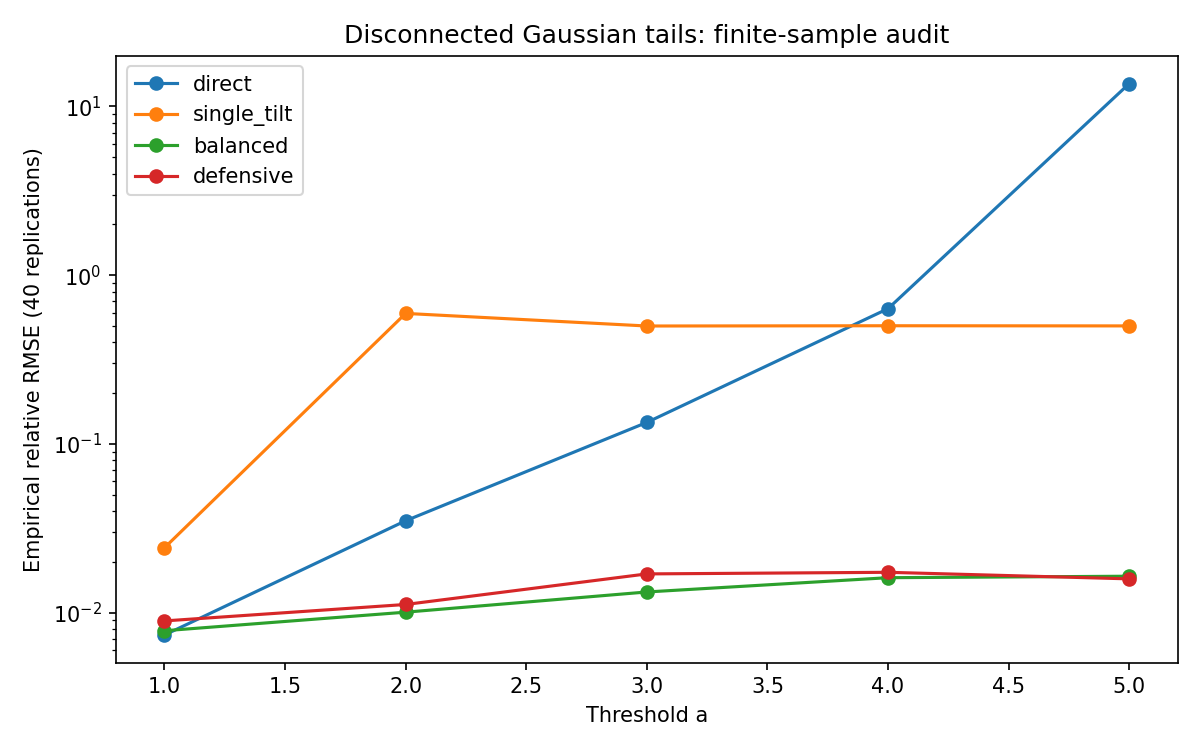

In [2]:
from IPython.display import Image, display
display(Image(filename='benchmarks/rmse.png'))

In [3]:
a=4.0
for m in ['direct','single_tilt','balanced','defensive']:
    print(m, 'true per-draw variance:', population_variance(a,m))
print('Exact event probability:', truth(a))

direct true per-draw variance: 6.333847139600271e-05
single_tilt true per-draw variance: 4443055.260253938
balanced true per-draw variance: 1.8099787045672554e-08
defensive true per-draw variance: 2.0555451246772345e-08
Exact event probability: 6.334248366623973e-05


## Conclusions
A proposal shifted to one tail remains unbiased in expectation but misses the other tail in finite samples and can report misleadingly small standard errors. The balanced mixture is a known remedy, not a new algorithm. Forty replications do not establish coverage calibration. This univariate synthetic experiment does not validate financial capital estimates or high-dimensional performance.